# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [1]:
import yfinance as yf
import pandas as pd

# Defino los tickers asignados
tickers = ['HD', 'JPM', 'OXY']

# Descargue los datos para el periodo especificado
datos = yf.download(tickers, start='2024-01-01', end='2026-01-01')

# Extraer únicamente los precios de cierre ajustados ('Adj Close') o de cierre ('Close')
precios_cierre = datos['Adj Close'] if 'Adj Close' in datos else datos['Close']

# Muestro las primeras 5 filas para validar la descarga
precios_cierre.head()

/tmp/ipykernel_1474/677458441.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download(tickers, start='2024-01-01', end='2026-01-01')
[*********************100%***********************]  3 of 3 completed


Ticker,HD,JPM,OXY
Date,,,
2024-01-02,321.653198,161.472702,57.020271
2024-01-03,315.296234,160.768936,57.552017
2024-01-04,315.603821,161.835861,56.137196
2024-01-05,319.658539,162.647797,55.966278
2024-01-08,324.309692,162.411758,55.330078


**Interpretación Analitica**



*   Se observa que descargue los precios de cierre diarios de mis tre activos selecionados (hd,jpm,oxy) comprende desde las fechas:  1 de enero de 2024 al 1 de enero de 2026, me muestra una estructura de series temporales sin valores nulos visibles en los primeros registros.


las series temporales me confirman una conexion de yfinance que funciono de manera adecuada. La lista de la base de datos necesaria para continuar con el analisis de calculo de rendimientos, volatilidad y matriz de correlación y varianza.


## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

In [2]:
# 1. Filtre y extraje únicamente los precios de cierre
if 'Close' in datos:
    df_cierre = datos['Close']
else:
    df_cierre = precios_cierre

# Verifico las primeras 5 filas de los precios de cierre
df_cierre.head()

Ticker,HD,JPM,OXY
Date,,,
2024-01-02,321.653198,161.472702,57.020271
2024-01-03,315.296234,160.768936,57.552017
2024-01-04,315.603821,161.835861,56.137196
2024-01-05,319.658539,162.647797,55.966278
2024-01-08,324.309692,162.411758,55.330078


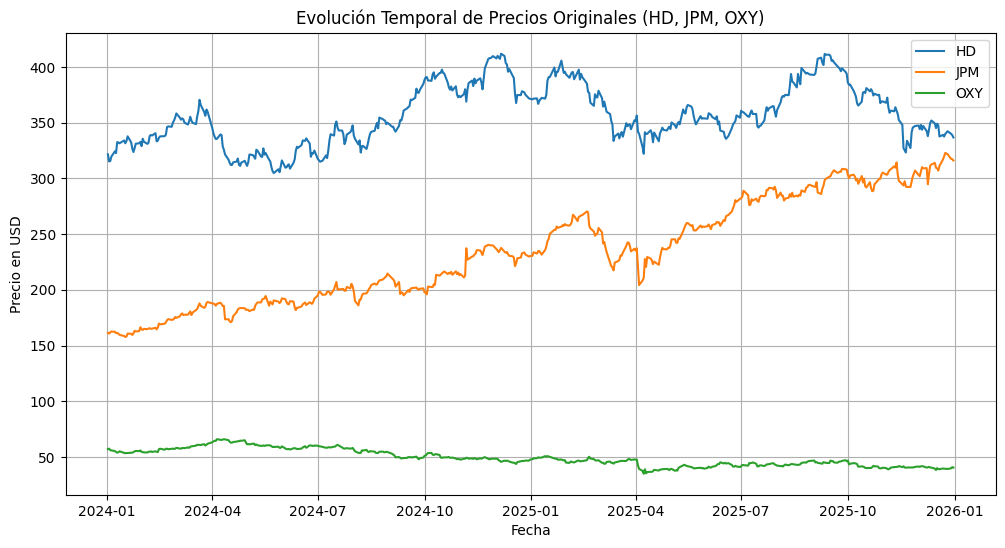

In [4]:
import matplotlib.pyplot as plt

# 2. Grafico en una sola figura la evolución temporal de los precios originales
plt.figure(figsize=(12, 6))
for columna in df_cierre.columns:
    plt.plot(df_cierre.index, df_cierre[columna], label=columna)

plt.title('Evolución Temporal de Precios Originales (HD, JPM, OXY)')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD')
plt.legend()
plt.grid(True)
plt.show()

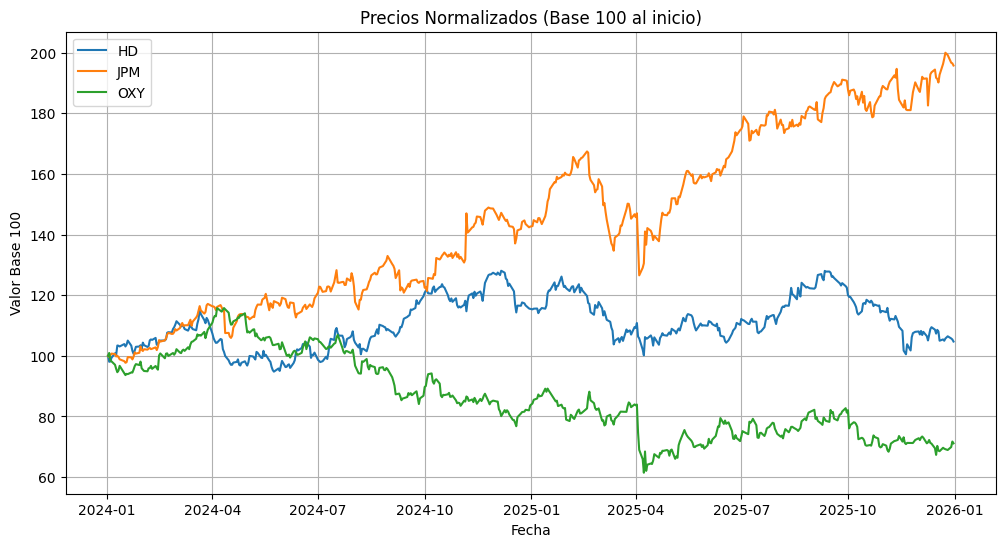

In [5]:
# 3. Realizo la normalización (base 100 en el primer registro)
df_normalizado = (df_cierre / df_cierre.iloc[0]) * 100

# Grafico nuevamente las series en otra figura
plt.figure(figsize=(12, 6))
for columna in df_normalizado.columns:
    plt.plot(df_normalizado.index, df_normalizado[columna], label=columna)

plt.title('Precios Normalizados (Base 100 al inicio)')
plt.xlabel('Fecha')
plt.ylabel('Valor Base 100')
plt.legend()
plt.grid(True)
plt.show()

**Interpretación**

* El comportamiento visual observado: En el gráfico de precios reales, los activos no se pueden comparar directamente porque cotizan a valores nominales muy distintos: El "hd" cotiza sobre los 300 USD, mientras que "oxy" maneja otros rangos. Esto ocasiona que el activo de mayor precio domine la escala visual y oculte las variaciones porcentuales de los demás.

* Justificació: El gráfico normalizado es metodológicamente superior para comparar rendimientos porque fija todos los activos en una base 100 en el primer registro.

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [6]:
import pandas as pd
import numpy as np

# 1. Calculo los rendimientos diarios porcentuales y eliminar valores nulos (NaN)
rendimientos = df_cierre.pct_change().dropna()

# Muestro las primeras 5 filas para validar
rendimientos.head()

Ticker,HD,JPM,OXY
Date,,,
2024-01-03,-0.019763,-0.004358,0.009326
2024-01-04,0.000976,0.006636,-0.024583
2024-01-05,0.012847,0.005017,-0.003045
2024-01-08,0.014550,-0.001451,-0.011368
2024-01-09,-0.005001,-0.007906,-0.013901


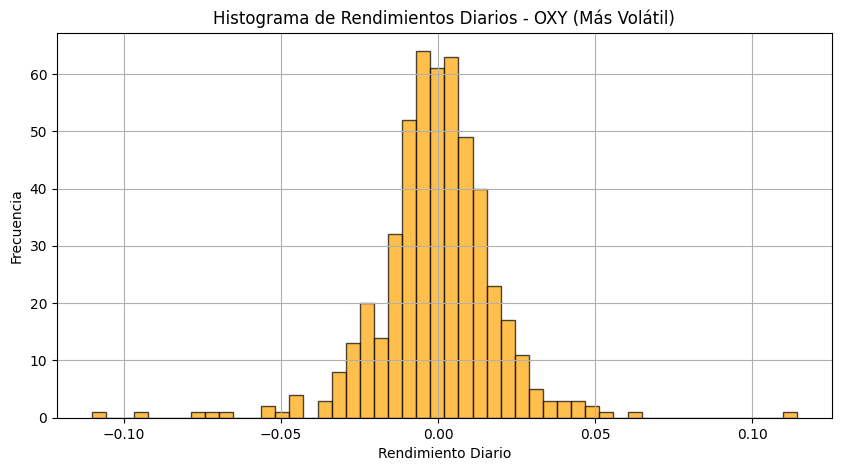

In [7]:
import matplotlib.pyplot as plt

# 2. GenerO un histograma para el activo más volátil (OXY)
activo_volatil = 'OXY'

plt.figure(figsize=(10, 5))
plt.hist(rendimientos[activo_volatil], bins=50, edgecolor='black', alpha=0.7, color='orange')
plt.title(f'Histograma de Rendimientos Diarios - {activo_volatil} (Más Volátil)')
plt.xlabel('Rendimiento Diario')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()

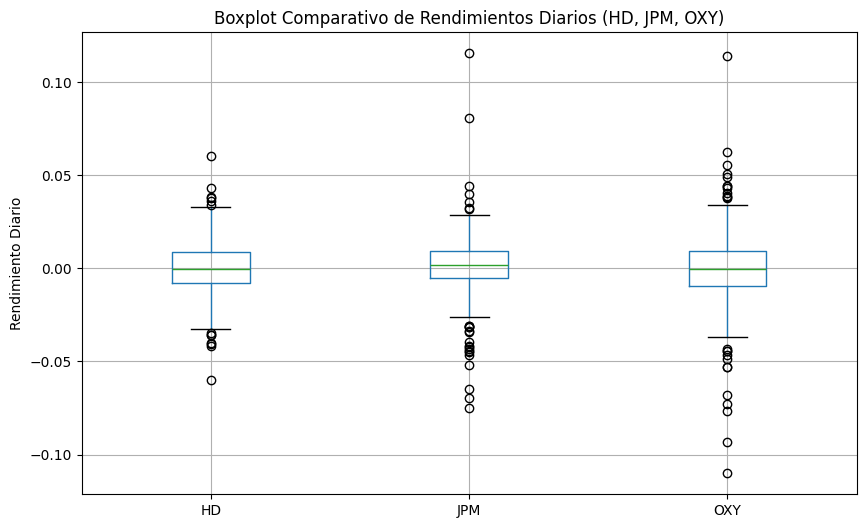

In [9]:
# 3. Diseño un Boxplot comparativo que muestre los rendimientos diarios de los 3 activos
plt.figure(figsize=(10, 6))
rendimientos.boxplot()
plt.title('Boxplot Comparativo de Rendimientos Diarios (HD, JPM, OXY)')
plt.ylabel('Rendimiento Diario')
plt.grid(True)
plt.show()


**Pregunta de Interpretación.**


¿Qué activo presenta la mayor dispersión y qué te dice esto sobre su riesgo?
  El activo con mayor dispersión:es "OXY". Esto indica que sus rendimientos diarios fluctúan en un rango más amplio en comparación con "HD"o "JPM", lo que se traduce estadísticamente en un mayor riesgo y mayor volatilidad para el inversionista.

* ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?
  se aprecian múltiples puntos aislados tanto en los valores positivos como negativos en las colas de las distribuciones de los tres activos. En el contexto económico reciente "periodo 2024-2026", estos valores atípicos representan días de alta volatilidad macroeconómica.

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

In [10]:
# 1. Calculo la matriz de correlación de Pearson para los rendimientos
matriz_corr = rendimientos.corr(method='pearson')

# Muestro la matriz resultante
matriz_corr

Ticker,HD,JPM,OXY
Ticker,,,
HD,1.000000,0.286175,0.232577
JPM,0.286175,1.000000,0.317686
OXY,0.232577,0.317686,1.000000


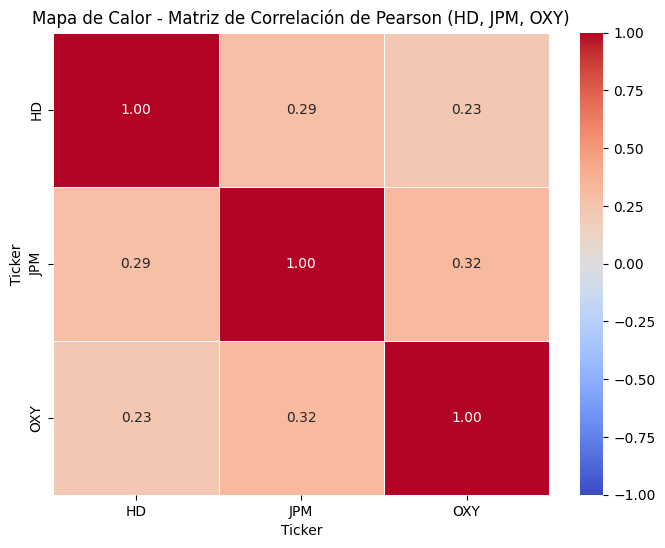

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Grafico un mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('Mapa de Calor - Matriz de Correlación de Pearson (HD, JPM, OXY)')
plt.show()

**Interpretación**

* ¿Existe alguna correlación fuerte entre alguno de tus activos?**
  No se observa una correlación fuerte cercana a 1 o -1 entre los activos analizados "HD, JPM y OXY". Los coeficientes de correlación se sitúan en niveles moderados o bajos, lo que indica que pertenecen a sectores económicos distintos.

* Si tuvieras que armar un portafolio de inversión buscando la diversificación minimizar el riesgo conjunto, ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?
  Para maximizar la diversificación y minimizar el riesgo conjunto, elegiría el par que presente el coeficiente de correlación más bajo o más cercano a cero dentro de la matriz. Al tener una menor sincronía en sus movimientos diarios, combinarlos en un portafolio permite que las caídas de uno puedan ser compensadas o amortiguadas por la estabilidad.

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [13]:
import pandas as pd
import numpy as np

# 1. Calculo estadísticas descriptivas más completas para los rendimientos diarios
resumen_avanzado = pd.DataFrame({
    'Media Diaria': rendimientos.mean(),
    'Mediana Diaria': rendimientos.median(),
    'Desviación Estándar': rendimientos.std(),
    'Varianza': rendimientos.var(),
    'Asimetría (Skew)': rendimientos.skew(),
    'Curtosis': rendimientos.kurtosis(),
    'Mínimo': rendimientos.min(),
    'Máximo': rendimientos.max(),
    'Rendimiento Acumulado': (1 + rendimientos).prod() - 1
})

# Tabla con mayor precisión decimal
resumen_avanzado.round(4)

,Media Diaria,Mediana Diaria,Desviación Estándar,Varianza,Asimetría (Skew),Curtosis,Mínimo,Máximo,Rendimiento Acumulado
Ticker,,,,,,,,,
HD,0.0002,-0.0006,0.0138,0.0002,0.0427,1.4701,-0.0602,0.0601,0.0471
JPM,0.0015,0.0017,0.0152,0.0002,0.1246,10.3377,-0.0748,0.1154,0.9578
OXY,-0.0005,-0.0002,0.0189,0.0004,-0.4139,6.7435,-0.1101,0.1141,-0.2888


**Conclusión Final para el Inversionista**


A partir del análisis financiero y estadístico realizado sobre el portafolio compuesto por "HD,JPM y OXY" para el periodo 2024-2026, le presentamos las siguientes conclusiones:

 **Relación Riesgo-Retorno:**
   * "JPM y HD" han demostrado un comportamiento más estable, presentando una menor desviación estándar en sus rendimientos diarios, lo que las posiciona como activos de menor volatilidad y riesgo moderado dentro de la cartera.
   * Por otro lado,"OXY" registra la mayor desviación estándar junto con el rango de variación más amplio entre sus valores mínimo y máximo. Esto evidencia un mayor nivel de riesgo y sensibilidad a choques del sector energético.

 **Estrategia de Diversificación:**
   * Las tres empresas pertenecen a sectores económicos marcadamente distintos. La matriz de correlación confirma que los activos no muestran una dependencia perfecta entre sí.
   * Se recomienda combinar activos de baja correlación: "HD o JPM con OXY" para construir un portafolio eficientE, logrando así suavizar la volatilidad total y optimizar la relación rendimiento.

In [14]:
# Genero resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)
resumen_stats = pd.DataFrame({
    'Media': rendimientos.mean(),
    'Mediana': rendimientos.median(),
    'Desviación Estándar': rendimientos.std(),
    'Mínimo': rendimientos.min(),
    'Máximo': rendimientos.max()
})

# Muestro la tabla resultante
resumen_stats

,Media,Mediana,Desviación Estándar,Mínimo,Máximo
Ticker,,,,,
HD,0.000186,-0.000579,0.013775,-0.060190,0.060106
JPM,0.001457,0.001673,0.015225,-0.074838,0.115445
OXY,-0.000500,-0.000176,0.018912,-0.110075,0.114096
